# UniRemington - Cali<br>Facultad de Ingeniería - Línea de Énfasis III: Análisis de Datos<br>(ↄ) Diego Fernando Marin, 2026-2

## Datos del Estudiante:

**Código**: <br>
**Nombre**: Diego Fernando Benitez Camacho

**Correo**: diego.benitez.9045@miremington.edu.co

# Taller #1 - Encuesta TV

## 0. Introducción

### ¿Qué vas a hacer en este taller?

Vas a realizar un **análisis exploratorio de datos (EDA)** sobre una encuesta de hábitos de televisión: quién ve qué, cuántas horas y cuánto paga por sus suscripciones. Lo harás con las dos librerías base del ecosistema de ciencia de datos en Python: **Pandas** (manipulación de tablas) y **Matplotlib** (gráficos).

### Alcance

Al terminar serás capaz de:

1. Inspeccionar un conjunto de datos nuevo (tamaño, tipos, valores faltantes).
2. Filtrar, contar, agrupar y ordenar con operaciones *vectorizadas* (sin recorrer filas con `for`).
3. Elegir y construir el gráfico adecuado para cada tipo de pregunta.
4. Contrastar hipótesis simples (¿hay diferencia entre hombres y mujeres?) y detectar *outliers*.
5. **Comunicar con honestidad** lo que los datos permiten (y no permiten) concluir.

## 1. Contexto del problema

Imagina que trabajas para un canal regional o una plataforma de *streaming* que quiere entender mejor a su audiencia. Se aplicó una encuesta corta a **68 personas** y la gerencia quiere respuestas a preguntas como:

- ¿Quiénes son los encuestados (edad, género)?
- ¿Qué canales son los más queridos y **quién los prefiere**? Esto orienta qué contenidos comprar o promocionar.
- ¿Ven más televisión los jóvenes o los adultos? Esto orienta **en qué franja** y con qué formato publicar.
- ¿Cuánto pagan por sus suscripciones y **qué tipo de persona paga más**? Esto orienta la política de precios.

**¿Por qué EDA y no directamente un modelo?** Porque antes de predecir hay que *entender*: un análisis exploratorio revela errores en los datos, patrones y preguntas nuevas, y evita construir modelos sobre supuestos falsos.

### Diccionario de datos

| Variable | Descripción | Tipo esperado |
|---|---|---|
| `nombre` | Nombre del encuestado | texto |
| `edad` | Edad en años | entero |
| `genero` | `M` (masculino) o `F` (femenino) | categórica |
| `canal_fav1`, `canal_fav2`, `canal_fav3` | Primer, segundo y tercer canal favorito | texto |
| `horas` | Horas de consumo de TV (horas x día) | entero |
| `costo_mes` | Costo mensual de suscripciones (pesos colombianos) | entero |

## 2. Preparación del entorno

Esta celda ya está completa: es el **ejemplo resuelto** que te muestra el estilo de las siguientes. Ejecútala y lee cada línea.

In [ ]:
# 1) Descarga el archivo y lo guarda como encuesta_tv.csv (en Colab/Jupyter, el "!" ejecuta un comando de consola)
!wget --no-verbose -O encuesta_tv.csv https://paste.c-net.org/WimpsPaolo

2026-10-27 21:55:41 URL:https://paste.c-net.org/WimpsPaolo [3134/3134] -> "encuesta_tv.csv" [1]


In [ ]:
# 2) Importamos las librerías con sus alias convencionales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# 3) Cargamos el CSV. OJO: el separador NO es coma, es una barra vertical "|"
df = pd.read_csv('encuesta_tv.csv', sep='|')

> **Teoría — separadores.** `read_csv` asume por defecto que las columnas están separadas por coma. Si el archivo usa otro carácter y no lo indicas con `sep=`, obtendrás **una sola columna** con todo pegado. Si te ocurre, ese es el primer sospechoso.

> **Alternativa sin `wget`:** `pd.read_csv('https://paste.c-net.org/WimpsPaolo', sep='|')` lee directamente desde la URL.

## Parte 1 — Primer contacto con los datos (Pasos 1–4)

> **Teoría.** Antes de calcular nada, un analista responde tres preguntas: *¿cuánto hay?* (dimensiones), *¿de qué tipo es cada columna?* (tipos y nulos) y *¿cómo se ve?* (muestras del inicio **y** del final; el final puede revelar registros agregados más tarde con otro formato).


### Paso 1. ¿Cuántos registros (filas) y variables (columnas) hay?

**Lógica:** `shape` devuelve una *tupla* `(filas, columnas)`.

In [ ]:
# Obtén las dimensiones del DataFrame.
# Pista: shape es un ATRIBUTO (no lleva paréntesis).
df.shape

(68, 8)

### Paso 2. ¿Cuáles son las variables, sus nombres y tipos?

**Lógica:** `info()` resume nombre, **cantidad de valores no nulos** y tipo (`dtype`) de cada columna. Compara el número de no nulos con el total de filas: ahí se descubren los datos faltantes.

In [ ]:
# Muestra el resumen estructural del DataFrame.
# Pista: info() es un MÉTODO (sí lleva paréntesis) e imprime directamente.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68 entries, 0 to 67
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   nombre      68 non-null     object
 1   edad        68 non-null     int64 
 2   genero      68 non-null     object
 3   canal_fav1  68 non-null     object
 4   canal_fav2  68 non-null     object
 5   canal_fav3  67 non-null     object
 6   horas       68 non-null     int64 
 7   costo_mes   68 non-null     int64 
dtypes: int64(3), object(5)
memory usage: 4.4+ KB


### Paso 3. Muestra las primeras 10 filas de los datos.

In [ ]:
# Muestra las 10 primeras filas.
# Pista: head(n) recibe el número de filas.
df.head(10)

,nombre,edad,genero,canal_fav1,canal_fav2,canal_fav3,horas,costo_mes
0,orlando,35,M,RCN,Telepacifico,HBO+,4,25000
1,jennifer,18,F,Caracol,RCN,Netflix,8,18000
2,julián,33,M,CNN,Star+,Disney+,5,23000
3,luisa,25,F,RCN,Caracol,Cinemax,6,15000
4,marcelo,16,M,Boomerang,Cartoon Network,Disney+,9,20000
5,guillermo,41,M,ESPN,ESPN2,Fox Sports,10,25000
6,stephany,11,F,Disney+,Star+,Amazon Prime,6,19000
7,mariana,32,F,Star+,HBO+,Paramount+,4,21000
8,juan,28,M,Fox,HBO+,Netflix,7,22000
9,andrea,20,F,Caracol,RCN,Netflix,5,19000


### Paso 4. Muestra las últimas 10 filas de los datos.

In [ ]:
# Muestra las 10 últimas filas.
# Pista: es el método "hermano" de head().
df.tail(10)


,nombre,edad,genero,canal_fav1,canal_fav2,canal_fav3,horas,costo_mes
58,paola,25,F,ESPN,ESPN2,Fox Sports,4,21000
59,juanita maria,34,F,HBO+,Netflix,Amazon Prime,6,23000
60,carlos andres,32,M,CNN,BBC,Discovery,5,24000
61,lina,23,F,HBO+,Netflix,Amazon Prime,7,20000
62,felipe andres,35,M,ESPN,ESPN2,Fox Sports,6,22000
63,maria,26,F,Netflix,HBO+,Disney+,5,21000
64,andres felipe,36,M,RCN,Caracol,Telepacifico,7,20000
65,juliana,24,F,ESPN,ESPN2,Fox Sports,4,22000
66,pablo,37,M,HBO+,Netflix,Amazon Prime,6,23000
67,juana,29,F,CNN,BBC,Discovery,5,21000


### Evaluación — Parte 1

- **E1.1 (conceptual).** En la salida de `info()` una columna muestra menos valores no nulos que las demás. ¿Cuál es y qué significa?

- **E1.2 (conceptual).** ¿Por qué `df.shape` se escribe sin paréntesis y `df.info()` con ellos?

- **E1.3 (código).** Obtén de una sola vez las estadísticas descriptivas (conteo, media, desviación, mínimo, cuartiles, máximo) de las columnas numéricas.

In [ ]:
# Reto E1.3 — Pista: existe un método cuyo nombre en inglés significa "describir".
df.describe()

,edad,horas,costo_mes
count,68.000000,68.000000,68.000000
mean,29.882353,6.102941,21470.588235
std,11.033909,1.497657,2215.754905
min,11.000000,4.000000,15000.000000
25%,21.750000,5.000000,20000.000000
50%,29.000000,6.000000,22000.000000
75%,37.000000,7.000000,23000.000000
max,53.000000,10.000000,27000.000000


## Parte 2 — Valores únicos, estadísticas y conteos (Pasos 5–8)

> **Teoría.** Tres herramientas que usarás todo el curso:
> - `Serie.unique()` → los valores distintos (como arreglo).
> - `Serie.nunique()` → **cuántos** valores distintos hay (ignora `NaN`).
> - `Serie.value_counts()` → cuántas veces aparece cada valor, ordenado de mayor a menor.


### Paso 5. ¿Cuáles son los nombres únicos de las personas encuestadas?

In [ ]:
# Obtén los nombres distintos de la columna 'nombre'.
# Pista: selecciona la columna con df['nombre'] y aplica el método de valores únicos.
df['nombre'].value_counts()

,count
nombre,
andres felipe,2
jennifer,1
orlando,1
julián,1
luisa,1
...,...
felipe andres,1
maria,1
juliana,1


### Paso 6. ¿Cuántos canales únicos hay y cuáles son?

**Lógica:** los canales están repartidos en **tres columnas**. Para contarlos como un solo conjunto primero hay que *apilar* las tres columnas en una sola Serie con `pd.concat([...])`.


In [ ]:
# 1. Apila canal_fav1, canal_fav2 y canal_fav3 en una sola Serie (guárdala en la variable 'canales').
# 2. Muestra los canales distintos con unique().
# 3. Cuenta cuántos hay con nunique() y compara con len(canales.unique()).
canales = pd.concat([df['canal_fav1'], df['canal_fav2'], df['canal_fav3']], ignore_index=True)
print(canales.unique())
print(canales.nunique())
print(len(canales.unique()))

['RCN' 'Caracol' 'CNN' 'Boomerang' 'ESPN' 'Disney+' 'Star+' 'Fox'
 'Teleantioquia' 'Warner' 'Netflix' 'HBO+' 'Cartoon Network' 'Disney'
 'Discovery' 'Telepacifico' 'ESPN2' 'TNT' 'BBC' 'Fox Sports' 'NatGeo'
 'Cinemax' 'Amazon Prime' 'Paramount+' 'Sony' 'GolTV' 'Nickelodeon'
 'History' nan]
28
29


> **Advertencia — `NaN` es un valor.** `unique()` **incluye** el valor faltante (`NaN`) como si fuera un canal; `nunique()` lo ignora. Si cuentas con `len(unique())` obtendrás un canal "fantasma".

### Paso 7. ¿Cuál es el promedio de edad?

In [ ]:
# Calcula la edad promedio.
# Pista: df['edad'] + método de la media.
# Exploración extra: prueba .min(), .max(), .median(), .sum(), .count()
df['edad'].mean()
df['edad'].min()
df['edad'].max()
df['edad'].median()
df['edad'].sum()
df['edad'].count()
print(f"Promedio: {df['edad'].mean():.1f}")
print(f"Mínima:   {df['edad'].min()}")
print(f"Máxima:   {df['edad'].max()}")
print(f"Mediana:  {df['edad'].median()}")
print(f"Suma:     {df['edad'].sum()}")
print(f"Conteo:   {df['edad'].count()}")

Promedio: 29.9
Mínima:   11
Máxima:   53
Mediana:  29.0
Suma:     2032
Conteo:   68


> Los métodos de resumen de una Serie incluyen `.min()`, `.max()`, `.median()`, `.sum()`, `.count()` y `.value_counts()`. (En el comentario del cuaderno original aparece escrito `values_count`, que **no existe**: el nombre correcto es `value_counts`.)

### Paso 8. ¿Cuántos encuestados son hombres y cuántas mujeres?

Resuelve el conteo de DOS formas.

In [ ]:
# Forma A: value_counts() sobre la columna 'genero'.
df['genero'].value_counts()

,count
genero,
M,35
F,33


In [ ]:
# Forma B: df.groupby('genero') seguido de .size()
df.groupby('genero').size()

,0
genero,
F,33
M,35


### Evaluación — Parte 2

- **E2.1 (conceptual).** En el Paso 6, ¿por qué `len(canales.unique())` y `canales.nunique()` dan resultados distintos? ¿Cuál es la cifra correcta de canales?

- **E2.2 (código).** `nombre` tiene menos valores únicos que filas. Encuentra **todas** las filas cuyo nombre está repetido. ¿Son la misma persona?

In [ ]:
# Pista E2.2 -> duplicated(keep=False) marca TODAS las filas repetidas, no solo la segunda aparición.
df.duplicated(keep=False)


,0
0,False
1,False
2,False
3,False
4,False
...,...
63,False
64,False
65,False
66,False


- **E2.3 (código).** Calcula el **porcentaje** de hombres y de mujeres (no la cantidad).

In [ ]:
# Pista E2.3 -> value_counts() tiene un parámetro que devuelve proporciones (multiplica por 100).
df['genero'].value_counts(normalize=True) * 100

,proportion
genero,
M,51.470588
F,48.529412


- **E2.4 (código + conceptual).** Calcula la **mediana** de edad y compárala con la media. ¿Qué te dice la diferencia?

In [ ]:
# Pista E2.4 -> .median()
df['edad'].median()

29.0

## Parte 3 — Filtros y rankings de frecuencia (Pasos 9–11)


> **Teoría — filtrado booleano.** Una condición sobre una columna (`df['edad'] >= 18`) produce una Serie de `True/False`, llamada **máscara**. Al pasarla a `df[...]` quedan solo las filas `True`. Se combinan con `&` (y), `|` (o) y `~` (no), **cada condición entre paréntesis**.

### Paso 9. Muestra los nombres de los hombres mayores de edad

In [ ]:
# 1. Crea la máscara 'filtro' combinando (genero == 'M') y (edad >= 18) con &.
filtro = (df['genero'] == 'M') & (df['edad'] >= 18)
df[filtro]


,nombre,edad,genero,canal_fav1,canal_fav2,canal_fav3,horas,costo_mes
0,orlando,35,M,RCN,Telepacifico,HBO+,4,25000
2,julián,33,M,CNN,Star+,Disney+,5,23000
5,guillermo,41,M,ESPN,ESPN2,Fox Sports,10,25000
8,juan,28,M,Fox,HBO+,Netflix,7,22000
10,carlos,37,M,ESPN,ESPN2,Fox Sports,6,24000
12,diego,22,M,Warner,HBO+,Sony,8,21000
14,felipe,24,M,Netflix,HBO+,Disney+,7,22000
16,oscar,40,M,Fox,ESPN,ESPN2,9,25000
18,daniel,30,M,ESPN,ESPN2,Fox Sports,5,24000
20,luis,36,M,Caracol,RCN,Teleantioquia,8,22000


In [ ]:
# 2. Aplica la máscara a df y muestra solo la columna 'nombre'.
df[filtro]['nombre']

,nombre
0,orlando
2,julián
5,guillermo
8,juan
10,carlos
12,diego
14,felipe
16,oscar
18,daniel
20,luis


> **Antipatrón — no recorras filas con `for`.** El cuaderno original muestra una versión con `df.iterrows()` y la marca como lo que **NO** se debe hacer: obliga a Python a procesar fila por fila, mientras que la máscara booleana opera sobre toda la columna en código compilado. Con 68 filas no notarás la diferencia; con 10 millones, sí.

In [ ]:
# Esto es lo que NO se debe hacer, no es optimo! obliga a usar filas:
for index, datos in df[['nombre', 'genero', 'edad']].iterrows():
    if datos.genero == 'M' and datos.edad >= 18:
        print(datos.nombre)

orlando
julián
guillermo
juan
carlos
diego
felipe
oscar
daniel
luis
pedro
rodrigo
jose
sergio
carlos alberto
carlos enrique
pedro jose
luis alberto
jose luis
miguel
juan pablo
camilo
roberto
alejandro
carlos andres
felipe andres
andres felipe
pablo


### Paso 10. ¿Cuáles son los 3 canales favoritos más comunes?

In [ ]:
# 1. Apila las tres columnas de canales (como en el Paso 6).
canales = pd.concat([df['canal_fav1'], df['canal_fav2'], df['canal_fav3']], ignore_index=True)
print(len(canales))
canales.head()

204


,0
0,RCN
1,Caracol
2,CNN
3,RCN
4,Boomerang


In [ ]:
# 2. Cuenta la frecuencia de cada canal con value_counts().
canales.value_counts()

,count
HBO+,25
Netflix,21
RCN,15
ESPN,15
Caracol,14
Fox Sports,14
Amazon Prime,14
Disney+,10
ESPN2,9
Discovery,8


In [ ]:
# 3. Quédate con los 3 primeros con head(3).
canales.value_counts().head(3)

,count
HBO+,25
Netflix,21
RCN,15


### Paso 11. ¿Cuál es el canal favorito (`canal_fav1`) más popular entre hombres y entre mujeres?

In [ ]:
# Agrupa por 'genero', toma la columna 'canal_fav1' y cuenta con value_counts().
# Pista: df.groupby(...)[...].value_counts()
# Reto extra: muestra solo los 3 primeros de cada género (investiga .groupby(level=0).head(3)).
df.groupby('genero')['canal_fav1'].value_counts()
df.groupby('genero')['canal_fav1'].value_counts().groupby(level=0).head(3)

genero  canal_fav1     
F       HBO+                9
        Caracol             5
        CNN                 4
M       ESPN               12
        HBO+                5
        Cartoon Network     4
Name: count, dtype: int64

### Evaluación — Parte 3

- **E3.1 (conceptual).** ¿Por qué en el Paso 9 se escribe `&` y no `and`, y por qué cada condición va entre paréntesis?

In [ ]:
(df['genero'] == 'M') & (df['edad'] >= 18)

,0
0,True
1,False
2,True
3,False
4,False
...,...
63,False
64,True
65,False
66,True


- **E3.2 (código).** ¿Cuántas **mujeres menores de edad** hay y cómo se llaman?


In [ ]:
menores_f = (df['genero'] == 'F') & (df['edad'] < 18)
print(menores_f.sum())
print(df.loc[menores_f, 'nombre'].tolist())

3
['stephany', 'ana maria', 'juanita']


- **E3.3 (código + conceptual).** Muestra el **top 5** de canales del Paso 10. ¿Qué observas en el tercer puesto? ¿Qué problema crea `head(3)`?


In [ ]:
canales.value_counts().head(5)

,count
HBO+,25
Netflix,21
RCN,15
ESPN,15
Caracol,14


- **E3.4 (código).** El Paso 11 solo mira `canal_fav1`. Repite el análisis considerando **los tres** canales favoritos. *Pista:* `df.melt(id_vars='genero', value_vars=[...], value_name='canal')` convierte tres columnas en una sola columna larga. ¿Cambia la conclusión?

In [ ]:
largo = df.melt(
    id_vars='genero',
    value_vars=['canal_fav1', 'canal_fav2', 'canal_fav3'],
    value_name='canal'
)

por_genero = largo.groupby('genero')['canal'].value_counts()
por_genero

genero  canal          
F       HBO+               16
        Netflix            14
        Caracol            11
        RCN                11
        Amazon Prime        9
        BBC                 4
        CNN                 4
        Discovery           4
        Disney+             4
        Teleantioquia       4
        Star+               3
        ESPN                2
        ESPN2               2
        Fox Sports          2
        Telepacifico        2
        Cartoon Network     1
        Cinemax             1
        Disney              1
        Nickelodeon         1
        Paramount+          1
        TNT                 1
        Warner              1
M       ESPN               13
        Fox Sports         12
        HBO+                9
        ESPN2               7
        Netflix             7
        Disney+             6
        Amazon Prime        5
        Boomerang           5
        Cartoon Network     5
        GolTV               5
        Discovery           4
        RCN                 4
        CNN                 3
        Caracol             3
        Telepacifico        3
        BBC                 2
        Fox                 2
        History             2
        NatGeo              2
        Disney              1
        Sony                1
        Star+               1
        Teleantioquia       1
        Warner              1
Name: count, dtype: int64

## Parte 4 — Relaciones entre variables y extremos (Pasos 12–14)

> **Teoría — correlación de Pearson.** `Serie_a.corr(Serie_b)` mide la **relación lineal** entre dos variables numéricas, entre −1 y +1:
> - cercana a **+1**: cuando una sube, la otra tiende a subir;
> - cercana a **−1**: cuando una sube, la otra tiende a bajar;
> - cercana a **0**: *no hay relación lineal* (¡pero puede haber otra forma de relación!).
>
> **Correlación no implica causalidad.**


### Paso 12. ¿Hay relación entre la edad y las horas de consumo de TV?

In [ ]:
r = df['edad'].corr(df['horas'])
print(f"Correlación edad-horas: {r:.3f}")

Correlación edad-horas: -0.027


### Paso 13. ¿Cuál es el costo promedio mensual de suscripciones?

In [ ]:
# Calcula el promedio de la columna 'costo_mes'.
df['costo_mes'].mean()

np.float64(21470.58823529412)

### Paso 14. ¿Cuál es el encuestado más joven y cuál el de mayor edad?

**Lógica:** no basta con el valor mínimo; queremos **quién** es. `idxmin()` / `idxmax()` devuelven la *etiqueta de la fila* donde ocurre el mínimo/máximo, y con `.loc[...]` recuperas esa fila completa.


In [ ]:
mas_joven = df.loc[df['edad'].idxmin()]
mayor     = df.loc[df['edad'].idxmax()]
print("Más joven:\n", mas_joven, "\n")
print("Mayor:\n", mayor)


Más joven:
 nombre            stephany
edad                    11
genero                   F
canal_fav1         Disney+
canal_fav2           Star+
canal_fav3    Amazon Prime
horas                    6
costo_mes            19000
Name: 6, dtype: object 

Mayor:
 nombre         jose luis
edad                  53
genero                 M
canal_fav1          ESPN
canal_fav2    Fox Sports
canal_fav3           NaN
horas                 10
costo_mes          27000
Name: 48, dtype: object


### Evaluación — Parte 4

- **E4.1 (conceptual).** Si en el Paso 12 obtuviste una correlación cercana a 0, ¿puedes afirmar que la edad **no influye** en las horas de TV? Justifica.


/tmp/ipykernel_1678/2768788611.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('grupo_edad')['horas'].mean()


,horas
grupo_edad,
<18,7.400000
18-30,5.642857
31-50,5.962963
>50,7.333333


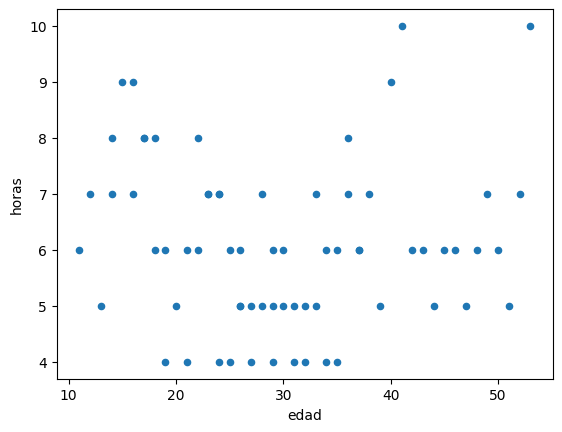

In [ ]:
df.plot.scatter(x='edad', y='horas')
df['grupo_edad'] = pd.cut(df['edad'], bins=[0, 17, 30, 50, 120],
                          labels=['<18', '18-30', '31-50', '>50'])
df.groupby('grupo_edad')['horas'].mean()

- **E4.2 (código).** Verifica tu respuesta anterior: compara el promedio de horas de los **menores de 18** contra los **adultos**. *Pista:* `df.groupby(df['edad'] < 18)['horas'].mean()`.


In [ ]:
df.groupby(df['edad'] < 18)['horas'].mean()

,horas
edad,
False,5.87931
True,7.40000


- **E4.3 (código).** Calcula la correlación entre `edad` y `costo_mes`. ¿Qué tan fuerte es?


In [ ]:
r = df['edad'].corr(df['costo_mes'])
print(f"Correlación edad-costo_mes: {r:.3f}")
df[['edad', 'horas', 'costo_mes']].corr().round(3)



Correlación edad-costo_mes: 0.650


,edad,horas,costo_mes
edad,1.000,-0.027,0.650
horas,-0.027,1.000,0.066
costo_mes,0.650,0.066,1.000


- **E4.4 (código).** Obtén la edad mínima y máxima **por género** en una sola instrucción (`groupby` + `agg`).


In [ ]:
df.groupby('genero')['edad'].agg(['min', 'max'])

,min,max
genero,,
F,11,51
M,12,53


## Parte 5 — Visualización básica (Pasos 15–18)

> **Teoría — ¿qué gráfico para qué pregunta?**
>
> | Pregunta | Gráfico |
> |---|---|
> | Cuántos hay en cada categoría | Barras |
> | Qué parte del total es cada categoría (pocas categorías) | Pie / torta |
> | Cómo se distribuye una variable numérica | Barras sobre conteos o histograma |
> | Cómo se relacionan dos variables numéricas | Dispersión (*scatter*) |
> | Composición dentro de cada categoría | Barras apiladas |
>
> **Regla de oro:** todo gráfico lleva **título**, **etiquetas de ejes** y, si hay varias series, **leyenda**.


### Paso 15. Gráfico de barras: distribución de edades

In [ ]:
import matplotlib.pyplot as plt

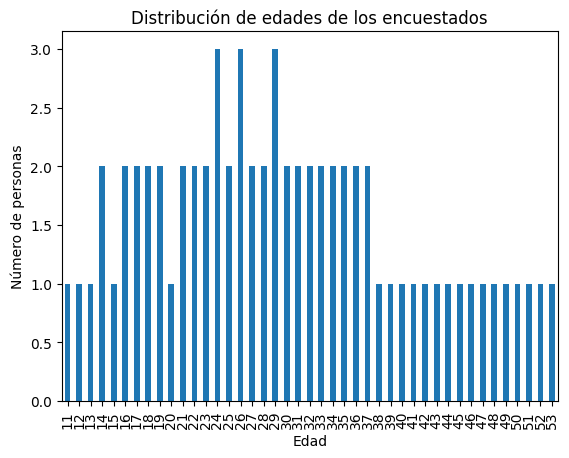

In [ ]:
conteo_edades = df['edad'].value_counts().sort_index()
conteo_edades.plot(kind='bar')
plt.title('Distribución de edades de los encuestados')
plt.xlabel('Edad')
plt.ylabel('Número de personas')
plt.show()


### Paso 16. Gráfico de pie: distribución de géneros


In [ ]:
import matplotlib.pyplot as plt

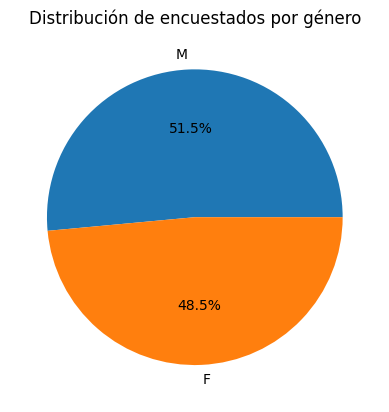

In [ ]:
conteo_genero = df['genero'].value_counts()

conteo_genero.plot(kind='pie', autopct='%1.1f%%')
plt.title('Distribución de encuestados por género')
plt.ylabel('')
plt.show()


### Paso 17. Barras apiladas: los 3 canales favoritos por género

**Lógica:** necesitas una tabla con canales en las filas y géneros en las columnas (`pd.crosstab`), restringida a los 3 canales más frecuentes, y luego graficarla con `stacked=True`.


In [ ]:
import matplotlib.pyplot as plt

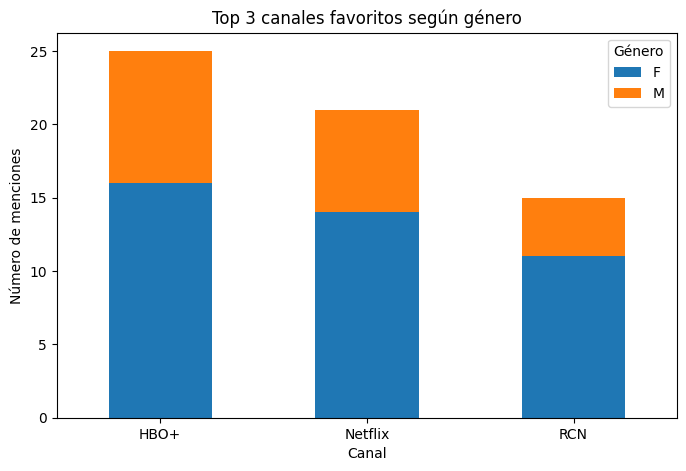

In [ ]:
largo = df.melt(
    id_vars='genero',
    value_vars=['canal_fav1', 'canal_fav2', 'canal_fav3'],
    value_name='canal'
)


top3 = largo['canal'].value_counts().head(3).index


tabla = pd.crosstab(largo['canal'], largo['genero']).loc[top3]
tabla


tabla.plot(kind='bar', stacked=True, figsize=(8, 5))
plt.title('Top 3 canales favoritos según género')
plt.xlabel('Canal')
plt.ylabel('Número de menciones')
plt.xticks(rotation=0)
plt.legend(title='Género')
plt.show()


### Paso 18. Dispersión: edad vs. horas de consumo de TV


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

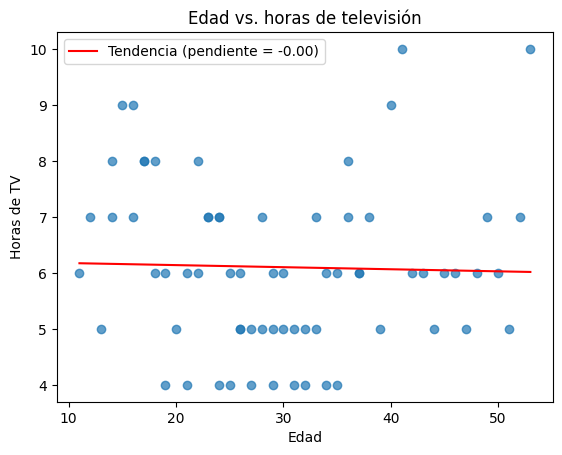

In [ ]:
x = df['edad']
y = df['horas']

plt.scatter(x, y, alpha=0.7)
plt.title('Edad vs. horas de televisión')
plt.xlabel('Edad')
plt.ylabel('Horas de TV')


m, b = np.polyfit(x, y, 1)
xs = np.linspace(x.min(), x.max(), 100)
plt.plot(xs, m * xs + b, color='red', label=f'Tendencia (pendiente = {m:.2f})')
plt.legend()

plt.show()


### Evaluación — Parte 5

- **E5.1 (conceptual).** El gráfico del Paso 15 tiene muchas barras muy delgadas (una por cada edad distinta). ¿Qué gráfico resumiría mejor la distribución y por qué?


El gráfico que resume mejor la distribución es el histograma (con un número razonable de intervalos o bins).

Por qué:

Agrupa en rangos en lugar de valores sueltos. El gráfico de barras del Paso 15 crea una barra por cada edad exacta (19, 20, 21...). Con 68 personas, la mayoría de edades aparecen 1 o 2 veces, así que las barras son bajas, delgadas y casi iguales. Eso es ruido: no deja ver dónde se concentra la gente

In [ ]:
import matplotlib.pyplot as plt

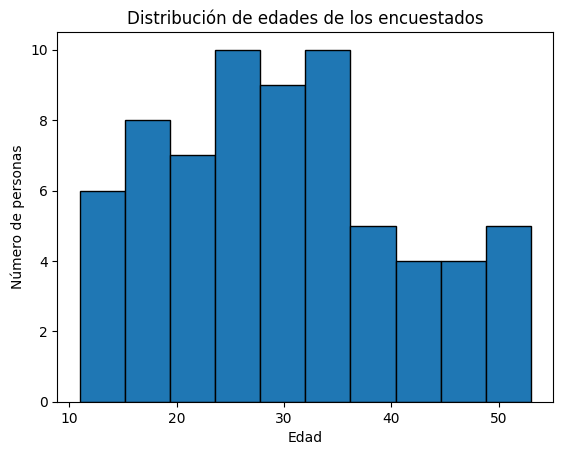

In [ ]:
df['edad'].plot(kind='hist', bins=10, edgecolor='black')
plt.title('Distribución de edades de los encuestados')
plt.xlabel('Edad')
plt.ylabel('Número de personas')
plt.show()

- **E5.2 (conceptual).** ¿En qué situaciones un gráfico de pie es mala idea?


Un gráfico de pie es mala idea cuando la comparación visual se vuelve difícil o engañosa

- **E5.3 (código).** Construye un histograma de `horas`.


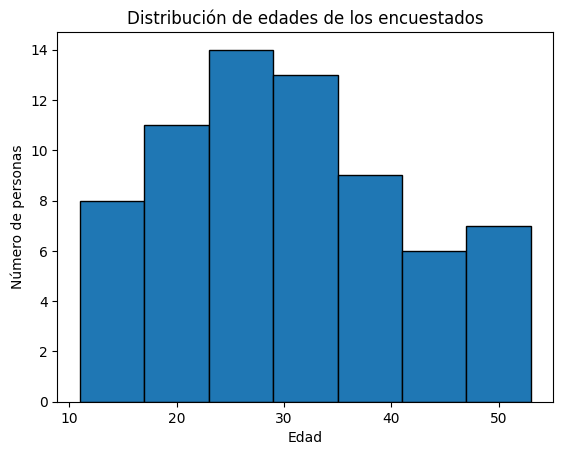

In [ ]:
df['edad'].plot(kind='hist', bins=7, edgecolor='black')
plt.title('Distribución de edades de los encuestados')
plt.xlabel('Edad')
plt.ylabel('Número de personas')
plt.show()



- **E5.4 (conceptual).** Mirando el gráfico del Paso 17: ¿qué canal de los tres tiene más aficionadas que aficionados? ¿Y la relación sigue igual para todos?


Los tres. En cada barra el azul (F) supera al naranja (M). La mayor diferencia en conteos está en HBO+ (16 vs. 9, unas 7 más), seguida de Netflix (14 vs. 7, unas 7 más) y RCN (11 vs. 4, unas 7 más). La diferencia absoluta es parecida en los tres.

## Parte 6 — Rankings y agrupaciones (Pasos 19, 20, 22, 23)

> **Teoría — tres patrones muy frecuentes.**
> 1. **Ranking:** `df.nlargest(n, 'col')` / `df.nsmallest(n, 'col')` (equivale a ordenar y tomar los primeros).
> 2. **Discretizar:** `pd.cut(serie, bins=[...], labels=[...])` convierte una variable numérica en **grupos por rangos**. Los intervalos son **cerrados a la derecha**: `(9, 20]` incluye el 20 y excluye el 9.
> 3. **Agrupar y resumir:** `df.groupby('grupo')['col'].mean()`.


### Paso 19. Los 5 encuestados con mayor costo mensual (y grafícalos)


In [ ]:
import matplotlib.pyplot as plt

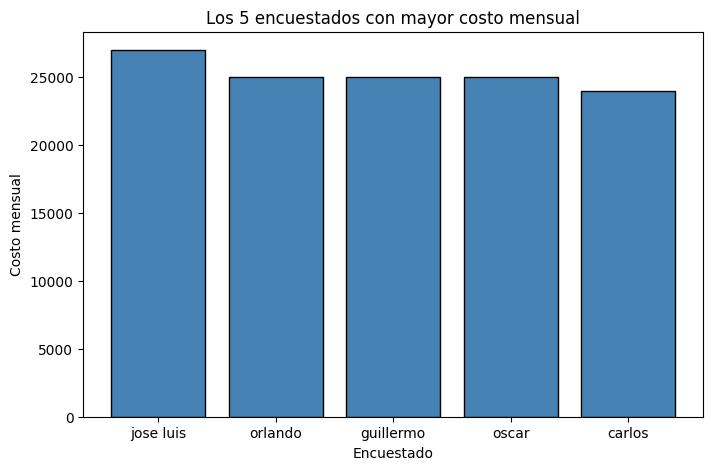

In [ ]:
top5 = df.nlargest(5, 'costo_mes')
top5[['nombre', 'edad', 'genero', 'costo_mes']]

plt.figure(figsize=(8, 5))
plt.bar(top5['nombre'], top5['costo_mes'], color='steelblue', edgecolor='black')
plt.title('Los 5 encuestados con mayor costo mensual')
plt.xlabel('Encuestado')
plt.ylabel('Costo mensual')
plt.show()

### Paso 20. Costo promedio mensual por grupo de edad (10-20, 21-30, ...)


In [ ]:
import matplotlib.pyplot as plt

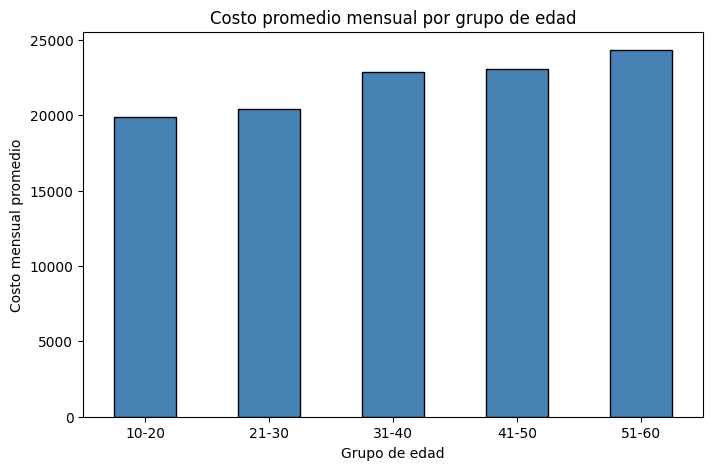

In [ ]:
bins = [9, 20, 30, 40, 50, 60]
etiquetas = ['10-20', '21-30', '31-40', '41-50', '51-60']

df['grupo_edad'] = pd.cut(df['edad'], bins=bins, labels=etiquetas)

costo_por_grupo = df.groupby('grupo_edad', observed=True)['costo_mes'].mean()
costo_por_grupo

costo_por_grupo.plot(kind='bar', color='steelblue', edgecolor='black', figsize=(8, 5))
plt.title('Costo promedio mensual por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Costo mensual promedio')
plt.xticks(rotation=0)
plt.show()

### Paso 22. Los 3 canales más populares entre los de 30 años o más


In [ ]:
import matplotlib.pyplot as plt

Encuestados de 30 años o más: 32


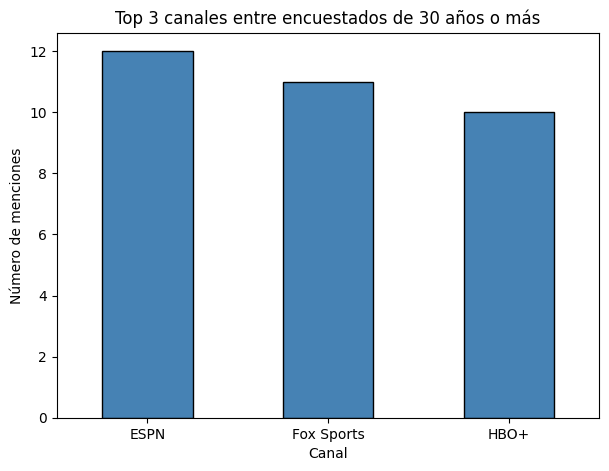

In [ ]:
# 1. Filtra df para quedarte con edad >= 30.
mayores = df[df['edad'] >= 30]
print(f"Encuestados de 30 años o más: {len(mayores)}")

# 2. Apila sus tres columnas de canales y cuenta con value_counts().
canales_30 = pd.concat(
    [mayores['canal_fav1'], mayores['canal_fav2'], mayores['canal_fav3']],
    ignore_index=True
)
conteo_30 = canales_30.value_counts()

# 3. Toma el top 3 y grafícalo.
top3_30 = conteo_30.head(3)
top3_30

top3_30.plot(kind='bar', color='steelblue', edgecolor='black', figsize=(7, 5))
plt.title('Top 3 canales entre encuestados de 30 años o más')
plt.xlabel('Canal')
plt.ylabel('Número de menciones')
plt.xticks(rotation=0)
plt.show()

### Paso 23. Barras horizontales: los 5 encuestados con más horas de TV


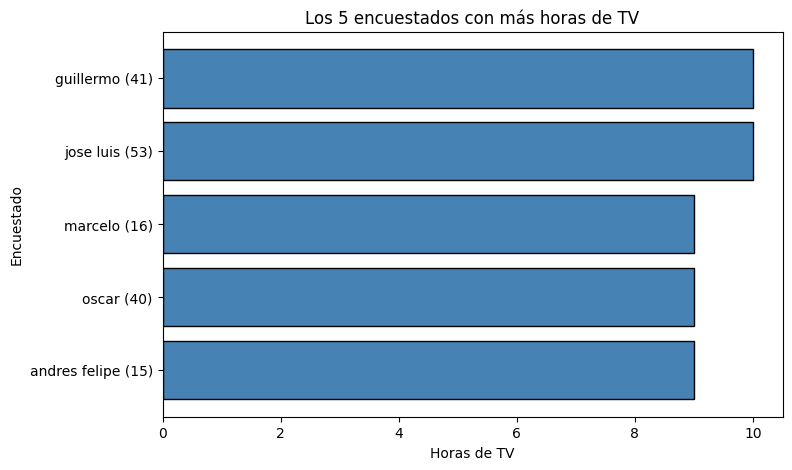

In [ ]:
import matplotlib.pyplot as plt


top5 = df.nlargest(5, 'horas')

etiquetas = top5['nombre'] + ' (' + top5['edad'].astype(str) + ')'

plt.figure(figsize=(8, 5))
plt.barh(etiquetas, top5['horas'], color='steelblue', edgecolor='black')
plt.title('Los 5 encuestados con más horas de TV')
plt.xlabel('Horas de TV')
plt.ylabel('Encuestado')
plt.gca().invert_yaxis()
plt.show()

### Evaluación — Parte 6

- **E6.1 (conceptual + código).** En el Paso 19, ¿qué ocurre con el 5.º lugar? Cuenta cuántas personas pagan lo mismo que quien quedó en el 5.º puesto. Investiga el parámetro `keep='all'` de `nlargest`.


Aquí el 5.º puesto es carlos, con ≈ 24.000. Los puestos 2, 3 y 4 sí están empatados (≈ 25.000), pero ese empate queda dentro del top 5 y no afecta el corte

In [ ]:
top5 = df.nlargest(5, 'costo_mes')
costo_5to = top5['costo_mes'].min()

n_igual = (df['costo_mes'] == costo_5to).sum()
print(f"Costo del 5.º puesto: {costo_5to}")
print(f"Personas que pagan lo mismo: {n_igual}")

top_todos = df.nlargest(5, 'costo_mes', keep='all')
print(f"Filas con keep='all': {len(top_todos)}")
top_todos[['nombre', 'edad', 'genero', 'costo_mes']]

Costo del 5.º puesto: 24000
Personas que pagan lo mismo: 9
Filas con keep='all': 13


,nombre,edad,genero,costo_mes
48,jose luis,53,M,27000
0,orlando,35,M,25000
5,guillermo,41,M,25000
16,oscar,40,M,25000
10,carlos,37,M,24000
18,daniel,30,M,24000
24,rodrigo,38,M,24000
33,carolina,44,F,24000
37,margarita,47,F,24000
41,carlos enrique,49,M,24000


- **E6.2 (código).** ¿Cuántas personas hay en cada grupo de edad del Paso 20? ¿Por qué importa saberlo antes de interpretar los promedios?


In [ ]:
df['grupo_edad'].value_counts().sort_index()

,count
grupo_edad,
10-20,15
21-30,23
31-40,17
41-50,10
51-60,3


- **E6.3 (conceptual).** En el Paso 23 aparece el nombre `andres felipe`. ¿Qué problema puede causar usar `nombre` como etiqueta?


los nombres no son identificadores únicos. Si dos encuestados se llaman andres felipe (o si una misma persona aparece dos veces), plt.barh dibuja dos barras con exactamente la misma etiqueta y no hay forma de saber cuál es cuál. Peor, el lector puede pensar que es una sola persona repetida, o que el gráfico tiene un error.

- **E6.4 (conceptual).** El costo promedio crece con el grupo de edad. ¿Puedes concluir que "envejecer hace que la gente gaste más en suscripciones"? Relaciónalo con E4.3.


Que el costo promedio suba con el grupo de edad es una asociación, y “envejecer hace que la gente gaste más” es una afirmación causal. Los datos solo dicen que, en esta muestra, los grupos mayores pagan en promedio más.

## Parte 7 — Análisis crítico: diferencias, asociaciones y outliers (Pasos 21, 24, 25)

Esta es la parte donde pasas de **describir** a **argumentar**. Aquí un número solo no basta: hay que preguntarse si es *grande*, si es *confiable* y si es *justo* compararlo.

> **Teoría — prueba de hipótesis en una línea.** Para comparar dos grupos se plantea:
> - **H₀:** no hay diferencia real entre los grupos (lo observado es azar).
> - **H₁:** sí hay diferencia.
>
> La prueba entrega un **p-valor**: la probabilidad de observar una diferencia *al menos tan grande* si H₀ fuera cierta. Si `p < 0.05` (nivel de significancia habitual) se rechaza H₀. **Un p-valor pequeño no dice que la diferencia sea importante, solo que es poco probable que sea azar.**


### Paso 21. ¿Hay diferencias significativas en el costo mensual entre hombres y mujeres?


In [ ]:
import matplotlib.pyplot as plt
from scipy import stats

            mean      std  count
genero                          
F       20393.94  2060.63     33
M       22485.71  1868.81     35


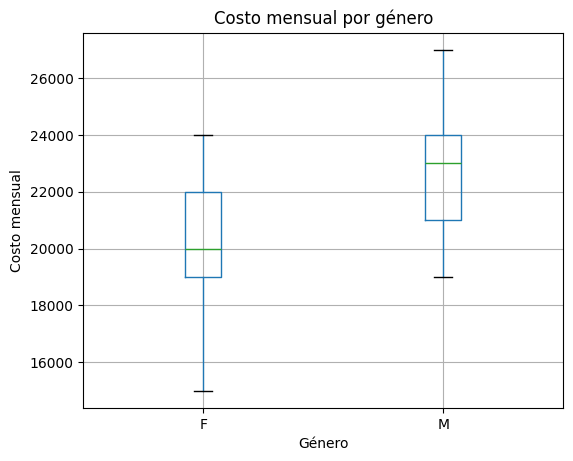

t = 4.376 | p-valor = 0.0000


In [ ]:
resumen = df.groupby('genero')['costo_mes'].agg(['mean', 'std', 'count']).round(2)
print(resumen)

df.boxplot(column='costo_mes', by='genero', figsize=(6, 5))
plt.title('Costo mensual por género')
plt.suptitle('')
plt.xlabel('Género')
plt.ylabel('Costo mensual')
plt.show()

hombres = df.loc[df['genero'] == 'M', 'costo_mes'].dropna()
mujeres = df.loc[df['genero'] == 'F', 'costo_mes'].dropna()

t, p = stats.ttest_ind(hombres, mujeres, equal_var=False)
print(f"t = {t:.3f} | p-valor = {p:.4f}")


### Paso 24. ¿Hay relación entre el género y los canales favoritos?

**Lógica:** una tabla de contingencia (`pd.crosstab`) cuenta cuántos hombres y mujeres eligieron cada canal. Si el género no importara, la proporción hombre/mujer sería parecida en todos los canales.


In [ ]:
import pandas as pd
from scipy import stats

In [ ]:
largo = df.melt(
    id_vars='genero',
    value_vars=['canal_fav1', 'canal_fav2', 'canal_fav3'],
    value_name='canal'
).dropna(subset=['canal'])


tabla = pd.crosstab(largo['canal'], largo['genero'])


tabla['total'] = tabla.sum(axis=1)
tabla = tabla.sort_values('total', ascending=False)
top10 = tabla.head(10)
top10

chi2, p, gl, esperados = stats.chi2_contingency(tabla.drop(columns='total'))
print(f"chi2 = {chi2:.2f} | gl = {gl} | p-valor = {p:.4f}")

chi2 = 59.05 | gl = 27 | p-valor = 0.0004


> **Advertencia — chi-cuadrado con muestras pequeñas.** Esa prueba exige conteos esperados razonablemente grandes por celda. Con 28 canales y 68 personas, muchas celdas quedan casi vacías: toma el p-valor como **orientación exploratoria**, no como veredicto.


### Paso 25. Outliers en `horas` y `costo_mes` y su impacto

> **Teoría — dos reglas para detectar outliers.**
> - **Regla IQR:** `IQR = Q3 − Q1`. Es atípico lo que queda fuera de `[Q1 − 1.5·IQR , Q3 + 1.5·IQR]`. Es la regla que dibuja los "bigotes" del boxplot.
> - **Regla z:** `z = (x − media) / desviación`. Se sospecha de `|z| > 2` (o 3 en muestras grandes).
>
> *Atípico no significa erróneo.* Antes de eliminar, pregunta si es un error de captura o un caso real.


In [ ]:
import matplotlib.pyplot as plt

Atípicos en horas (IQR): 0
Empty DataFrame
Columns: [nombre, edad, genero, horas]
Index: []

Atípicos en costo_mes (IQR): 1
  nombre  edad genero  costo_mes
3  luisa    25      F      15000

Atípicos en horas (z): 2
       nombre  edad  horas
5   guillermo    41     10
48  jose luis    53     10

Atípicos en costo_mes (z): 2
       nombre  edad  costo_mes
3       luisa    25      15000
48  jose luis    53      27000


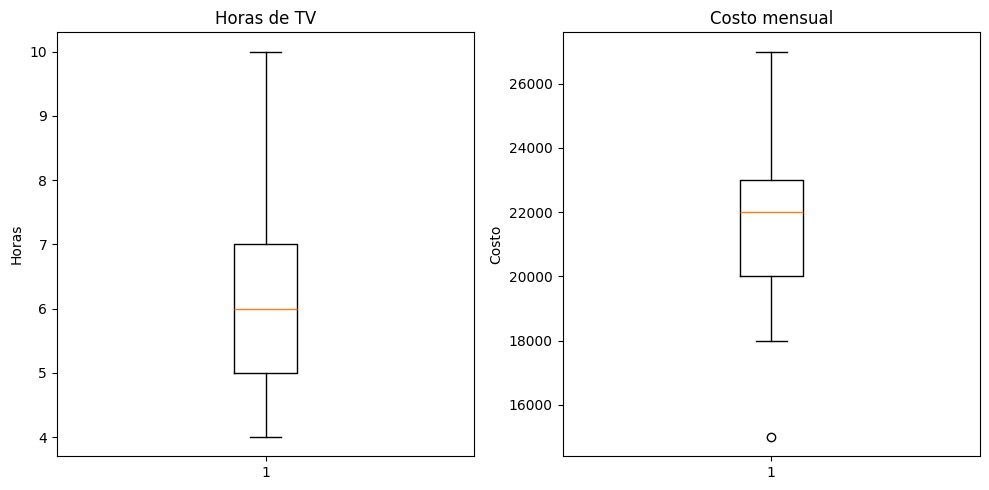

            con atípicos  sin atípicos
media            21470.6       21567.2
desviación        2215.8        2083.3
mediana          22000.0       22000.0
n                   68.0          67.0


In [ ]:
def outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr
    return (serie < limite_inf) | (serie > limite_sup)


mask_h = outliers_iqr(df['horas'])
mask_c = outliers_iqr(df['costo_mes'])

print("Atípicos en horas (IQR):", mask_h.sum())
print(df.loc[mask_h, ['nombre', 'edad', 'genero', 'horas']])

print("\nAtípicos en costo_mes (IQR):", mask_c.sum())
print(df.loc[mask_c, ['nombre', 'edad', 'genero', 'costo_mes']])


def outliers_z(serie, umbral=2):
    z = (serie - serie.mean()) / serie.std()
    return z.abs() > umbral

mask_hz = outliers_z(df['horas'])
mask_cz = outliers_z(df['costo_mes'])

print("\nAtípicos en horas (z):", mask_hz.sum())
print(df.loc[mask_hz, ['nombre', 'edad', 'horas']])

print("\nAtípicos en costo_mes (z):", mask_cz.sum())
print(df.loc[mask_cz, ['nombre', 'edad', 'costo_mes']])

fig, ejes = plt.subplots(1, 2, figsize=(10, 5))
ejes[0].boxplot(df['horas'].dropna())
ejes[0].set_title('Horas de TV')
ejes[0].set_ylabel('Horas')
ejes[1].boxplot(df['costo_mes'].dropna())
ejes[1].set_title('Costo mensual')
ejes[1].set_ylabel('Costo')
plt.tight_layout()
plt.show()


con = df['costo_mes']
sin = df.loc[~mask_c, 'costo_mes']

impacto = pd.DataFrame({
    'con atípicos': [con.mean(), con.std(), con.median(), con.count()],
    'sin atípicos': [sin.mean(), sin.std(), sin.median(), sin.count()]
}, index=['media', 'desviación', 'mediana', 'n']).round(1)
print(impacto)

### Evaluación — Parte 7

- **E7.1 (conceptual).** En el Paso 21 obtuviste un p-valor muy inferior a 0.05. Explica con tus palabras qué significa y qué **no** significa.


Un p-valor muy inferior a 0.05 significa que, si no hubiera diferencia real entre el costo mensual de hombres y mujeres, sería muy improbable observar una diferencia tan grande como la de la muestra; por eso se rechaza H₀ y hay evidencia estadística de diferencia. No significa que la diferencia sea grande o relevante en la práctica, ni que el género sea la causa, ni que H₀ tenga una probabilidad tan baja de ser cierta

- **E7.2 (código + conceptual).** Calcula la **edad promedio por género**. Sabiendo que la edad correlaciona con el costo (E4.3), ¿qué advertencia harías sobre la conclusión del Paso 21?


In [ ]:
df.groupby('genero')['edad'].agg(['mean', 'median', 'std', 'count']).round(1)

,mean,median,std,count
genero,,,,
F,28.2,26.0,10.5,33
M,31.5,33.0,11.4,35


 la diferencia de costo entre géneros del Paso 21 podría deberse en parte a la diferencia de edad entre los grupos y no al género en sí. Por eso, aunque el p-valor sea menor a 0.05, no se puede concluir que el género determine el costo: habría que comparar a igual edad (por grupos de edad o con una regresión)

- **E7.3 (código).** Calcula la media y desviación de `costo_mes` **sin** los outliers detectados por la regla z. ¿Cuánto cambian?


In [ ]:
mask_cz = outliers_z(df['costo_mes'])

con = df['costo_mes']
sin = df.loc[~mask_cz, 'costo_mes']

impacto_z = pd.DataFrame({
    'con atípicos': [con.mean(), con.std(), con.median(), con.count()],
    'sin atípicos (z)': [sin.mean(), sin.std(), sin.median(), sin.count()]
}, index=['media', 'desviación', 'mediana', 'n'])


impacto_z['cambio'] = impacto_z['sin atípicos (z)'] - impacto_z['con atípicos']
impacto_z['cambio_%'] = (impacto_z['cambio'] / impacto_z['con atípicos'] * 100)

print(f"Atípicos detectados con z: {mask_cz.sum()}")
print(impacto_z.round(1))

Atípicos detectados con z: 2
            con atípicos  sin atípicos (z)  cambio  cambio_%
media            21470.6           21484.8    14.3       0.1
desviación        2215.8            1986.4  -229.3     -10.3
mediana          22000.0           22000.0     0.0       0.0
n                   68.0              66.0    -2.0      -2.9


- **E7.4 (conceptual).** ¿Es correcto eliminar automáticamente a los outliers? Da un argumento a favor y uno en contra.


no es correcto eliminar los outliers automáticamente. A favor: si son errores de captura (por ejemplo, un valor imposible de horas o un costo con un cero de más), distorsionan la media, la desviación y las pruebas estadísticas, y conviene corregirlos o quitarlos. En contra: si son casos reales (como un cliente que paga mucho más por varios planes), eliminarlos borra información relevante para el negocio y sesga las conclusiones, además de reducir una muestra que ya es pequeña. Lo adecuado es investigar cada caso, eliminar solo los errores comprobados y verificar con un análisis de sensibilidad (con y sin atípicos)

## Conclusión

Redacta, en un máximo de **5 líneas** y sin usar código, las conclusiones que presentarías a la gerencia del canal: *quién ve qué, cuánto ve y cuánto paga*. Para cada afirmación, indica el **paso** del que proviene y una **limitación** (por ejemplo: muestra de solo 68 personas, posibles errores de captura, grupos de edad desbalanceados).


Quién ve qué: HBO+, Netflix y RCN son los canales más mencionados, y en los tres predominan las mujeres. (Pasos 10 y 17; limitación: muestra de solo 68 personas, y si hay más mujeres que hombres en la encuesta, el predominio puede reflejar la muestra y no una preferencia real.)

Cuánto ven: la edad por sí sola no basta para saber quién ve más televisión, así que conviene comparar por grupos de edad antes de decidir franjas y formatos. (Pasos 12 y E4.2; limitación: la correlación solo mide relación lineal y el grupo de menores puede ser muy pequeño.)

Cuánto pagan: el costo mensual tiende a subir con la edad, con pagos máximos cercanos a 27.000. (Pasos 19 y 20; limitación: grupos de edad desbalanceados y valores atípicos que inflan el promedio.)

Quién paga más: existe una diferencia de costo entre hombres y mujeres, pero parte de ella puede deberse a la edad y no al género. (Ppasos 21 y E7.2; limitación: asociación no es causalidad y la edad no está controlada.)

Calidad de los datos: los hallazgos son orientativos, no definitivos. (Pasos 1 a 4 y 25; limitación: posibles errores de captura, nombres repetidos y atípicos no verificados.)